# Fine-Tune MPNet with LoRA/PEFT for ITSM Ticket Similarity (v3)

**Model:** sentence-transformers/all-mpnet-base-v2
**Method:** LoRA (Low-Rank Adaptation) fine-tuning
**Data:** Pre-generated curriculum pairs (easy â†’ medium â†’ hard)
**Goal:** Beat baseline Spearman 0.504

---

## Changelog (v3)

- âœ… Consolidated all imports into single cell (Cell 3)
- âœ… Fixed section numbering (Score Distribution before Evaluation)
- âœ… Removed dead code (pair generation, legacy training blocks)
- âœ… Cleaned up if-guards and conditional execution
- âœ… Consolidated device detection
- âœ… **Preserved all fixes:** train_pairs_path, epochs=12, lr=CONFIG['lr']
- âœ… Clear linear execution flow (no hidden branches)

---


## ðŸ“‹ Quick Configuration Summary

| Component | Setting | Rationale |
|-----------|---------|-----------|
| **LoRA Rank** | 16 | Balanced capacity (8=low, 32=high) |
| **LoRA Alpha** | 32 | Standard scaling (2Ã—rank) |
| **Target Modules** | q_proj, v_proj | Attention query/value projections |
| **Learning Rate** | 1e-4 | Lower than full fine-tune (2e-5) |
| **MNRL Weight** | 0.9 | Primary ranking loss |
| **Cosine Weight** | 0.1 | Auxiliary calibration |
| **Batch Size** | 16 (8 on MPS) | Auto-adjusted for device |
| **Epochs** | 4 | 2 phases Ã— 2 epochs each |

**Key Metrics to Watch:**
- **Trainable params**: Should be ~3-5M (vs ~30-50M baseline)
- **Spearman correlation**: Target > 0.75 (current V2 best: 0.7516)
- **ROC-AUC**: Target > 0.93 (current V2 best: 0.9369)
- **F1 @ optimal threshold**: Target > 0.84 (current V2 best: 0.8442)

In [1]:
# =============================================================================
# IMPORTS (Consolidated)
# =============================================================================

# Standard library
import os
import sys
import json
import random
import subprocess
import re
from pathlib import Path
from datetime import datetime

# Data & ML
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    roc_auc_score, 
    precision_recall_curve, 
    f1_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_curve
)
from scipy.stats import spearmanr, pearsonr

# Sentence Transformers
from sentence_transformers import SentenceTransformer, InputExample, losses
from sentence_transformers.evaluation import EmbeddingSimilarityEvaluator
from torch.utils.data import DataLoader

# LoRA/PEFT
from peft import LoraConfig, get_peft_model, TaskType

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Utilities
from tqdm import tqdm
import logging
import gc
import warnings

print('[OK] All imports loaded successfully')



[OK] All imports loaded successfully


## 1. Environment Setup

Configure warnings, check packages, and detect compute device (GPU/MPS/CPU).


In [2]:
# Suppress warnings
warnings.filterwarnings('ignore')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

# Logging setup
logging.basicConfig(level=logging.INFO, format='%(message)s')
log = logging.info

# Install required packages if missing
try:
    import peft
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'peft>=0.4.0'])
    import peft

# Device detection
if torch.cuda.is_available():
    DEVICE = 'cuda'
    device_name = torch.cuda.get_device_name(0)
    print(f'[DEVICE] Using CUDA: {device_name}')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    DEVICE = 'mps'
    print(f'[DEVICE] Using Apple Silicon MPS')
else:
    DEVICE = 'cpu'
    print(f'[DEVICE] Using CPU')

print(f'[TORCH] Version: {torch.__version__}')
print(f'[PEFT] Version: {peft.__version__}')



[DEVICE] Using CUDA: NVIDIA GeForce RTX 5090
[TORCH] Version: 2.9.1+cu130
[PEFT] Version: 0.18.0


## 2. Configuration

All training hyperparameters in one place.

**Key fixes applied:**
- `train_pairs_path`: curriculum_training_pairs_complete.json
- `epochs`: 12 (up from 6)
- `lr`: 5e-5 (LoRA-optimized learning rate)


In [3]:
# Simple logging
def log(msg, level=logging.INFO):
    print(msg)

# --- CONFIGURATION (V3 - Curriculum Learning with Pre-generated Pairs) ---
CONFIG = {
    # Model
    'model_name': 'sentence-transformers/all-mpnet-base-v2',
    'output_dir': 'models/real_servicenow_finetuned_mpnet_lora',

    # Data - USING PRE-GENERATED CURRICULUM PAIRS
    'use_pre_generated_pairs': True,  # NEW: Use pre-generated pairs
    'train_pairs_path': 'data_new/curriculum_training_pairs_complete.json',  # NEW: Curriculum dataset
    'source_data': 'data_new\\SNow_incident_ticket_data.csv',  # Fallback (not used)

    # LoRA/PEFT Configuration
    'use_lora': True,
    'lora_r': 16,              # Rank (8-32, higher = more capacity)
    'lora_alpha': 32,          # Scaling factor (typically 2*r)
    'lora_dropout': 0.1,       # Dropout for LoRA layers
    'lora_target_modules': ['query', 'key', 'value'],

    # Loss Function
    'use_multi_loss': False,   # Use single loss for simplicity
    'loss_type': 'cosine',     # 'cosine' or 'mnrl'

    # Training hyperparameters (UPDATED FOR CURRICULUM)
    'epochs': 12,              # 12 total epochs (4 per curriculum phase)
    'batch_size': 64,          # Will auto-reduce for MPS/CPU if needed
    'lr': 5e-5,                # REDUCED from 5e-5 (prevent catastrophic forgetting) (LoRA needs higher LR)
    'max_seq_length': 256,     # REDUCED from 384 (match baseline)
    'warmup_ratio': 0.15,

    # Curriculum Learning (NEW - Using phase_indicators from data)
    'use_curriculum': True,    # Train in 3 phases
    'use_legacy_mode': False,  # Legacy (non-curriculum) evaluation features
    'epochs_per_phase': 4,     # 4 epochs per phase (12 total / 3 phases)

    # Data splits (only used if NOT using pre-generated)
    'eval_split': 0.15,
    'holdout_split': 0.10,
    'min_text_length': 25,

    # Pair generation (LEGACY - not used with pre-generated pairs)
    'num_pairs': 50000,        # Not used
    'pos_ratio': 0.30,         # Not used

    # Reproducibility
    'seed': 42
}

# Set seeds
random.seed(CONFIG['seed'])
np.random.seed(CONFIG['seed'])
torch.manual_seed(CONFIG['seed'])

log("="*70)
log("CONFIGURATION (V3 - Curriculum Learning)")
log("="*70)
log(f"Model: {CONFIG['model_name']}")
log(f"Output: {CONFIG['output_dir']}")
log(f"\nData:")
log(f"  Using pre-generated pairs: {CONFIG['use_pre_generated_pairs']}")
log(f"  Pairs file: {CONFIG['train_pairs_path']}")
log(f"\nLoRA Config:")
log(f"  Rank: {CONFIG['lora_r']}")
log(f"  Alpha: {CONFIG['lora_alpha']}")
log(f"  Dropout: {CONFIG['lora_dropout']}")
log(f"\nTraining:")
log(f"  Total epochs: {CONFIG['epochs']}")
log(f"  Learning rate: {CONFIG['lr']} (INCREASED for LoRA)")
log(f"  Batch size: {CONFIG['batch_size']}")
log(f"  Max seq length: {CONFIG['max_seq_length']} (REDUCED to match baseline)")
log(f"\nCurriculum:")
log(f"  Use curriculum: {CONFIG['use_curriculum']}")
log(f"  Legacy mode: {CONFIG.get('use_legacy_mode', False)}")
log(f"  Epochs per phase: {CONFIG['epochs_per_phase']}")
log("="*70)



CONFIGURATION (V3 - Curriculum Learning)
Model: sentence-transformers/all-mpnet-base-v2
Output: models/real_servicenow_finetuned_mpnet_lora

Data:
  Using pre-generated pairs: True
  Pairs file: data_new/curriculum_training_pairs_complete.json

LoRA Config:
  Rank: 16
  Alpha: 32
  Dropout: 0.1

Training:
  Total epochs: 12
  Learning rate: 5e-05 (INCREASED for LoRA)
  Batch size: 64
  Max seq length: 256 (REDUCED to match baseline)

Curriculum:
  Use curriculum: True
  Legacy mode: False
  Epochs per phase: 4


## 3. Data Loading & Preprocessing

Load ServiceNow incident data from CSV.


In [4]:
def load_and_preprocess_real_data(config):
    """
    Load and preprocess real ServiceNow incident data.
    
    Key differences from dummy data:
    - Only 'Description' column (no 'Short Description')
    - Real data has multi-line descriptions with embedded newlines
    - Richer vocabulary and more varied text
    """
    source_path = Path(config['source_data'])
    
    # Debug: Show absolute path
    log(f"ðŸ” Looking for data file:")
    log(f"   Configured path: {config['source_data']}")
    log(f"   Absolute path: {source_path.resolve()}")
    log(f"   Current working directory: {Path.cwd()}")
    log(f"   File exists: {source_path.exists()}")
    
    if not source_path.exists():
        raise FileNotFoundError(f"Data file not found: {source_path.resolve()}")
    
    log(f"ðŸ“‚ Loading real ServiceNow data from: {source_path}")
    
    # Load CSV - handle multi-line fields
    df = pd.read_csv(source_path, encoding='utf-8', on_bad_lines='skip')
    initial_count = len(df)
    log(f"[STATS] Loaded {initial_count:,} raw records")
    
    # Check required columns
    required_cols = ['Number', 'Description', 'Category', 'Subcategory', 
                     'Service', 'Service offering', 'Assignment group']
    missing_cols = [col for col in required_cols if col not in df.columns]
    if missing_cols:
        log(f"[WARN] Missing columns: {missing_cols}")
        # Use available columns
        required_cols = [col for col in required_cols if col in df.columns]
    
    log(f"[OK] Available columns: {list(df.columns)}")
    
    # Clean text function
    def clean_text(text):
        if pd.isna(text) or text is None:
            return ""
        text = str(text).strip()
        # Normalize whitespace (collapse multiple spaces/newlines)
        text = re.sub(r'\s+', ' ', text)
        # Remove common boilerplate
        text = re.sub(r'Note\s*:\s*This is an automated.*?\.', '', text, flags=re.IGNORECASE)
        return text.strip()
    
    # Clean Description
    df['Description'] = df['Description'].apply(clean_text)
    
    # Fill NA for context columns
    context_cols = ['Category', 'Subcategory', 'Service', 'Service offering', 'Assignment group']
    for col in context_cols:
        if col in df.columns:
            df[col] = df[col].fillna('').astype(str).str.strip().str.lower()
    
    # Build contextual text representation
    # Format: "Description (Context: [Service|Offering] [Category|Subcategory] Group: X)"
    def build_context(row):
        parts = []
        
        # Service context
        service_parts = []
        if row.get('Service', ''):
            service_parts.append(row['Service'])
        if row.get('Service offering', ''):
            service_parts.append(row['Service offering'])
        if service_parts:
            parts.append(f"[{' | '.join(service_parts)}]")
        
        # Category context
        cat_parts = []
        if row.get('Category', ''):
            cat_parts.append(row['Category'])
        if row.get('Subcategory', ''):
            cat_parts.append(row['Subcategory'])
        if cat_parts:
            parts.append(f"[{' | '.join(cat_parts)}]")
        
        # Assignment group
        if row.get('Assignment group', ''):
            parts.append(f"Group: {row['Assignment group']}")
        
        return ' '.join(parts) if parts else ''
    
    # Build full text: Description + Context suffix
    df['context'] = df.apply(build_context, axis=1)
    df['text'] = df.apply(
        lambda row: f"{row['Description']} (Context: {row['context']})" if row['context'] else row['Description'],
        axis=1
    )
    
    # Filter out short/empty descriptions
    df = df[df['Description'].str.len() >= config['min_text_length']].copy()
    log(f"ðŸ“‰ After filtering short descriptions: {len(df):,} records (dropped {initial_count - len(df):,})")
    
    # Create category_id for stratified splitting
    if 'Category' in df.columns and 'Subcategory' in df.columns:
        df['category_id'] = df.groupby(['Category', 'Subcategory']).ngroup()
    else:
        df['category_id'] = 0
    
    # Reset index
    df = df.reset_index(drop=True)
    
    # Summary stats
    log(f"\n[STATS] Data Summary:")
    log(f"   Total records: {len(df):,}")
    log(f"   Unique categories: {df['category_id'].nunique()}")
    log(f"   Avg text length: {df['text'].str.len().mean():.0f} chars")
    log(f"   Min text length: {df['text'].str.len().min()} chars")
    log(f"   Max text length: {df['text'].str.len().max()} chars")
    
    # Sample text
    log(f"\nðŸ“ Sample preprocessed text:")
    log(f"   '{df['text'].iloc[0][:200]}...'")
    
    return df

# Load the data
df_incidents = load_and_preprocess_real_data(CONFIG)
print(f"\n[OK] Loaded {len(df_incidents):,} incidents ready for training")


ðŸ” Looking for data file:
   Configured path: data_new\SNow_incident_ticket_data.csv
   Absolute path: C:\Users\donov\Downloads\nexustism\nexustism\data_new\SNow_incident_ticket_data.csv
   Current working directory: c:\Users\donov\Downloads\nexustism\nexustism
   File exists: True
ðŸ“‚ Loading real ServiceNow data from: data_new\SNow_incident_ticket_data.csv
[STATS] Loaded 10,633 raw records
[OK] Available columns: ['Number', 'Description', 'Opened by', 'Company', 'ITSM Department', 'Created', 'Urgency', 'Impact', 'Priority', 'Assignment group', 'Assigned to', 'State', 'Service', 'Service offering', 'Closed', 'Closed by', 'Category', 'Subcategory', 'Resolution code', 'Resolution notes', 'User input', 'Comments and Work notes', 'Manday Effort (hrs)', 'Ticket Type', 'AMS Domain', 'AMS System Type', 'AMS Category Type', 'AMS Service Type', 'AMS Business Related', 'AMS IT Related']
ðŸ“‰ After filtering short descriptions: 10,486 records (dropped 147)

[STATS] Data Summary:
   Total reco

## 4. Data Splitting

Split into train/eval/holdout sets.


In [5]:
def split_data(df, config):
    """
    Three-way split: Train / Eval / Holdout
    - Holdout is completely unseen (for adversarial diagnostic)
    - Stratified by category to ensure representation
    """
    # Handle rare categories: group categories with <2 samples
    category_counts = df['category_id'].value_counts()
    rare_categories = category_counts[category_counts < 2].index
    
    # Create stratification column: use category_id for common categories, -1 for rare
    df['stratify_col'] = df['category_id'].copy()
    df.loc[df['category_id'].isin(rare_categories), 'stratify_col'] = -1
    
    # Check if we can stratify (need at least 2 samples per class)
    stratify_counts = df['stratify_col'].value_counts()
    can_stratify = all(stratify_counts >= 2)
    
    if can_stratify:
        # First split: separate holdout set (stratified)
        train_eval_df, holdout_df = train_test_split(
            df,
            test_size=config['holdout_split'],
            stratify=df['stratify_col'],
            random_state=config['seed']
        )
        
        # Second split: train/eval from remaining (stratified)
        train_df, eval_df = train_test_split(
            train_eval_df,
            test_size=config['eval_split'],
            stratify=train_eval_df['stratify_col'],
            random_state=config['seed']
        )
        log("[OK] Using stratified split")
    else:
        # Fallback: random split without stratification
        log("[WARN] Using random split (categories too imbalanced for stratification)")
        train_eval_df, holdout_df = train_test_split(
            df,
            test_size=config['holdout_split'],
            random_state=config['seed']
        )
        
        train_df, eval_df = train_test_split(
            train_eval_df,
            test_size=config['eval_split'],
            random_state=config['seed']
        )
    
    return train_df, eval_df, holdout_df

# Split the data
train_df, eval_df, holdout_df = split_data(df_incidents, CONFIG)

log(f"[STATS] Data Splits:")
log(f"   Train:   {len(train_df):,} incidents ({len(train_df)/len(df_incidents)*100:.1f}%)")
log(f"   Eval:    {len(eval_df):,} incidents ({len(eval_df)/len(df_incidents)*100:.1f}%)")
log(f"   Holdout: {len(holdout_df):,} incidents ({len(holdout_df)/len(df_incidents)*100:.1f}%)")

# Check for data leakage
def check_overlap(df1, df2, name1, name2):
    overlap = len(set(df1['Number']) & set(df2['Number']))
    log(f"   {name1} âˆ© {name2}: {overlap} incidents")

log(f"\nðŸ” Overlap Check:")
check_overlap(train_df, eval_df, "Train", "Eval")
check_overlap(train_df, holdout_df, "Train", "Holdout")
check_overlap(eval_df, holdout_df, "Eval", "Holdout")


[OK] Using stratified split
[STATS] Data Splits:
   Train:   8,021 incidents (76.5%)
   Eval:    1,416 incidents (13.5%)
   Holdout: 1,049 incidents (10.0%)

ðŸ” Overlap Check:
   Train âˆ© Eval: 0 incidents
   Train âˆ© Holdout: 0 incidents
   Eval âˆ© Holdout: 0 incidents


## 5. Load Pre-Generated Curriculum Pairs

Load curriculum pairs from JSON (Phase 1: easy, Phase 2: medium, Phase 3: hard).


In [6]:
# ========================================
# LOAD PRE-GENERATED CURRICULUM PAIRS
# ========================================


def load_curriculum_pairs(pairs_path, use_curriculum=True):
    """
    Load pre-generated curriculum pairs from JSON file.
    
    Args:
        pairs_path: Path to curriculum_training_pairs_*.json
        use_curriculum: If True, return separate phases; if False, return all mixed
    
    Returns:
        If use_curriculum=True: (phase1_pairs, phase2_pairs, phase3_pairs)
        If use_curriculum=False: all_pairs (mixed)
    """
    log(f"\nLoading curriculum pairs from: {pairs_path}")
    
    with open(pairs_path, 'r', encoding='utf-8') as f:
        data = json.load(f)
    
    texts1 = data['texts1']
    texts2 = data['texts2']
    labels = data['labels']
    phase_indicators = data.get('phase_indicators', [1] * len(labels))
    
    log(f"Loaded {len(labels):,} total pairs")
    log(f"  Positives: {sum(labels):,} ({100*sum(labels)/len(labels):.1f}%)")
    log(f"  Negatives: {len(labels) - sum(labels):,} ({100*(len(labels)-sum(labels))/len(labels):.1f}%)")
    
    # Show metadata
    metadata = data.get('metadata', {})
    if metadata:
        log(f"\nCurriculum phases: {metadata.get('curriculum_phases', 'N/A')}")
        for phase_num in [1, 2, 3]:
            phase_key = f'phase{phase_num}_config'
            if phase_key in metadata:
                phase_cfg = metadata[phase_key]
                log(f"  Phase {phase_num} ({phase_cfg.get('difficulty', 'N/A')}): "
                    f"{phase_cfg.get('pairs', 0):,} pairs, "
                    f"pos>={phase_cfg.get('pos_threshold', 'N/A')}, "
                    f"neg<={phase_cfg.get('neg_threshold', 'N/A')}")
    
    # Convert to InputExample format
    if use_curriculum:
        # Separate by phase
        phase1_pairs = []
        phase2_pairs = []
        phase3_pairs = []
        
        for i in range(len(labels)):
            example = InputExample(texts=[texts1[i], texts2[i]], label=float(labels[i]))
            phase = phase_indicators[i]
            if phase == 1:
                phase1_pairs.append(example)
            elif phase == 2:
                phase2_pairs.append(example)
            elif phase == 3:
                phase3_pairs.append(example)
        
        log(f"\nSeparated into phases:")
        log(f"  Phase 1: {len(phase1_pairs):,} pairs")
        log(f"  Phase 2: {len(phase2_pairs):,} pairs")
        log(f"  Phase 3: {len(phase3_pairs):,} pairs")
        
        return phase1_pairs, phase2_pairs, phase3_pairs
    else:
        # Return all mixed
        all_pairs = [
            InputExample(texts=[texts1[i], texts2[i]], label=float(labels[i]))
            for i in range(len(labels))
        ]
        log(f"Returning {len(all_pairs):,} mixed pairs")
        return all_pairs

# ========================================
# LOAD OR GENERATE PAIRS
# ========================================

if CONFIG.get('use_pre_generated_pairs', False):
    log("="*70)
    log("USING PRE-GENERATED CURRICULUM PAIRS")
    log("="*70)
    
    pairs_path = CONFIG['train_pairs_path']
    
    if CONFIG.get('use_curriculum', False):
        # Load phases separately for curriculum training
        phase1_train, phase2_train, phase3_train = load_curriculum_pairs(
            pairs_path, use_curriculum=True
        )
        
        # For now, combine for evaluation split
        # (In production, you'd want separate eval sets per phase)
        train_examples = phase1_train + phase2_train + phase3_train
        
        log(f"\nTotal training examples: {len(train_examples):,}")
        log("\nNote: Will train in 3 curriculum phases")
        
        # Store phases for later use
        CURRICULUM_PHASES = {
            'phase1': phase1_train,
            'phase2': phase2_train,
            'phase3': phase3_train
        }

# Verify curriculum loaded correctly
if CONFIG.get('use_curriculum') and CURRICULUM_PHASES:
    total_pairs = sum(len(v) for v in CURRICULUM_PHASES.values())
    print(f"\n[OK] Curriculum Verification:")
    print(f"   Total pairs: {total_pairs:,}")
    print(f"   Phase 1 (easy): {len(CURRICULUM_PHASES.get('phase1', [])):,}")
    print(f"   Phase 2 (medium): {len(CURRICULUM_PHASES.get('phase2', [])):,}")
    print(f"   Phase 3 (hard): {len(CURRICULUM_PHASES.get('phase3', [])):,}")
    
    assert len(CURRICULUM_PHASES) == 3, f"Expected 3 phases, got {len(CURRICULUM_PHASES)}"
    assert total_pairs == 15000, f"Expected 15K pairs, got {total_pairs:,}"
    
    # Load test/eval pairs from fixed_test_pairs.json
    test_pairs_path = 'data_new/fixed_test_pairs.json'
    log(f"\nLoading test pairs from: {test_pairs_path}")
    
    with open(test_pairs_path, 'r', encoding='utf-8') as f:
        test_data = json.load(f)
    
    # Convert to InputExample
    eval_examples = [
        InputExample(texts=[t1, t2], label=float(label))
        for t1, t2, label in zip(test_data['texts1'], test_data['texts2'], test_data['labels'])
    ]
    
    # For curriculum training, we don't have separate holdout/borderline
    # Use eval_examples for all evaluation metrics
    holdout_examples = eval_examples  # Reuse for holdout metrics
    borderline_examples = []  # Empty - not applicable for curriculum
    
    log(f"[OK] Loaded {len(eval_examples):,} test pairs for evaluation")
    pos_count = sum(1 for ex in eval_examples if ex.label == 1.0)
    log(f"   Positives: {pos_count:,} ({100*pos_count/len(eval_examples):.1f}%)")
    log(f"   Negatives: {len(eval_examples)-pos_count:,} ({100*(len(eval_examples)-pos_count)/len(eval_examples):.1f}%)")
    
    
    # Skip the pair generation cells below
    SKIP_PAIR_GENERATION = True
    
else:
    log("="*70)
    # eval_examples, holdout_examples, borderline_examples will be generated below
    log("GENERATING PAIRS ON-THE-FLY (LEGACY MODE)")
    log("="*70)
    log("Note: Consider using pre-generated curriculum pairs instead!")
    log("      Run fix_train_test_mismatch.ipynb to generate them.")
    
    SKIP_PAIR_GENERATION = False
    CURRICULUM_PHASES = None



USING PRE-GENERATED CURRICULUM PAIRS

Loading curriculum pairs from: data_new/curriculum_training_pairs_complete.json
Loaded 15,000 total pairs
  Positives: 10,000 (66.7%)
  Negatives: 5,000 (33.3%)

Curriculum phases: 3
  Phase 1 (easy): 5,000 pairs, pos>=0.52, neg<=0.36
  Phase 2 (medium): 5,000 pairs, pos>=0.4, neg<=0.45
  Phase 3 (hard): 5,000 pairs, pos>=0.3, neg<=0.5

Separated into phases:
  Phase 1: 5,000 pairs
  Phase 2: 5,000 pairs
  Phase 3: 5,000 pairs

Total training examples: 15,000

Note: Will train in 3 curriculum phases

[OK] Curriculum Verification:
   Total pairs: 15,000
   Phase 1 (easy): 5,000
   Phase 2 (medium): 5,000
   Phase 3 (hard): 5,000

Loading test pairs from: data_new/fixed_test_pairs.json
[OK] Loaded 1,000 test pairs for evaluation
   Positives: 500 (50.0%)
   Negatives: 500 (50.0%)


## 6. Training Functions & LoRA Setup

Define training utilities, evaluator class, and LoRA initialization.


In [7]:
from sentence_transformers.evaluation import SentenceEvaluator

# --- Custom Evaluator ---
class ITSMEvaluator(SentenceEvaluator):
    """Evaluator for ITSM ticket similarity."""
    
    def __init__(self, examples, batch_size=16, name=""):
        self.examples = examples
        self.batch_size = batch_size
        self.name = name
        
        self.texts1 = [ex.texts[0] for ex in examples]
        self.texts2 = [ex.texts[1] for ex in examples]
        self.labels = np.array([ex.label for ex in examples])
        
        self.csv_file = f"{name}_eval_results.csv"
        self.csv_headers = ["epoch", "steps", "spearman", "pearson", "roc_auc", "pr_auc"]
    
    def __call__(self, model, output_path=None, epoch=-1, steps=-1):
        model.eval()
        
        # Encode pairs
        emb1 = model.encode(self.texts1, batch_size=self.batch_size, 
                          show_progress_bar=False, convert_to_numpy=True)
        emb2 = model.encode(self.texts2, batch_size=self.batch_size, 
                          show_progress_bar=False, convert_to_numpy=True)
        
        # Compute cosine similarity
        scores = np.sum(emb1 * emb2, axis=1) / (
            np.linalg.norm(emb1, axis=1) * np.linalg.norm(emb2, axis=1) + 1e-8
        )
        
        # Compute metrics
        spearman, _ = spearmanr(self.labels, scores)
        pearson, _ = pearsonr(self.labels, scores)
        
        try:
            roc_auc = roc_auc_score(self.labels, scores)
            pr_auc = average_precision_score(self.labels, scores)
        except ValueError:
            roc_auc, pr_auc = 0.0, 0.0
        
        log(f"  [{self.name}] Epoch {epoch}: Spearman={spearman:.4f}, ROC-AUC={roc_auc:.4f}, PR-AUC={pr_auc:.4f}")
        
        # Save to CSV
        if output_path:
            csv_path = Path(output_path) / self.csv_file
            if not csv_path.exists():
                with open(csv_path, 'w') as f:
                    f.write(','.join(self.csv_headers) + '\n')
            with open(csv_path, 'a') as f:
                f.write(f"{epoch},{steps},{spearman},{pearson},{roc_auc},{pr_auc}\n")
        
        return spearman  # Primary metric


# --- Model Initialization with LoRA/PEFT ---
def init_model_with_lora(config, device):
    """Initialize model with optional LoRA/PEFT adapters."""
    # Clear GPU memory
    if device == 'cuda':
        torch.cuda.empty_cache()
    elif device == 'mps':
        torch.mps.empty_cache()
    gc.collect()
    
    log(f"ðŸ”§ Loading base model: {config['model_name']}")
    model = SentenceTransformer(config['model_name'], device=device)
    # Cap max sequence length to reduce memory footprint
    model.max_seq_length = min(config['max_seq_length'], 256)
    
    # Apply LoRA if enabled
    if config['use_lora']:
        
        # Inspect module names to find viable targets
        base_model = model[0].auto_model
        linear_names = [name for name, module in base_model.named_modules() if isinstance(module, nn.Linear)]
        configured_targets = config['lora_target_modules']
        resolved_targets = [t for t in configured_targets if any(t in n for n in linear_names)]
        
        if not resolved_targets:
            # Fallback heuristics for BERT/MPNet-like models
            priority = ['q_proj', 'k_proj', 'v_proj', 'query', 'key', 'value', 'dense']
            resolved_targets = [p for p in priority if any(p in n for n in linear_names)]
        
        if not resolved_targets:
            log("[ERROR] Could not find matching target modules for LoRA. Available linear submodules include:")
            sample = linear_names[:50]
            for n in sample:
                log(f"   - {n}")
            raise ValueError("LoRA target_modules could not be resolved; please adjust CONFIG['lora_target_modules'].")
        
        log(f"[TARGET] Applying LoRA adapters...")
        log(f"   Rank (r): {config['lora_r']}")
        log(f"   Alpha: {config['lora_alpha']}")
        log(f"   Target modules (resolved): {resolved_targets}")
        log(f"   Dropout: {config['lora_dropout']}")
        
        lora_config = LoraConfig(
            r=config['lora_r'],
            lora_alpha=config['lora_alpha'],
            target_modules=resolved_targets,
            lora_dropout=config['lora_dropout'],
            bias="none",
            task_type=TaskType.FEATURE_EXTRACTION,
        )
        
        # Apply PEFT wrapper
        peft_model = get_peft_model(base_model, lora_config)

        # Explicitly move PEFT model to device
        log(f"[GPU] Moving PEFT model to {device}")
        peft_model = peft_model.to(device)
        model[0].auto_model = peft_model
        
        # Enable gradient checkpointing to reduce memory
        try:
            model[0].auto_model.gradient_checkpointing_enable()
            log("[BUILD] Gradient checkpointing enabled")
        except Exception:
            pass
        
        # Print trainable parameters
        trainable_params = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)
        total_params = sum(p.numel() for p in peft_model.parameters())
        trainable_pct = 100 * trainable_params / total_params
        
        log(f"[OK] LoRA Applied!")
        log(f"   Trainable params: {trainable_params:,} ({trainable_pct:.2f}%)")
        log(f"   Total params: {total_params:,}")
        log(f"   Parameter reduction: {100 - trainable_pct:.2f}%")
    else:
        log(f"â„¹ï¸ Full fine-tuning (no LoRA)")
        total_params = sum(p.numel() for p in model.parameters())
        log(f"   Total params: {total_params:,}")
    
    log(f"[OK] Model loaded on {device}, max_seq_length={model.max_seq_length}")
    
    return model


# --- V2: Cross-Validated Threshold Selection ---
def get_cv_threshold(examples, model, n_folds=5):
    """
    V2 NEW: Use k-fold cross-validation to find robust threshold.
    
    Returns the average best threshold across folds.
    """
    
    texts1 = [ex.texts[0] for ex in examples]
    texts2 = [ex.texts[1] for ex in examples]
    labels = np.array([ex.label for ex in examples])
    
    # Encode all pairs
    emb1 = model.encode(texts1, batch_size=CONFIG['batch_size'], show_progress_bar=False)
    emb2 = model.encode(texts2, batch_size=CONFIG['batch_size'], show_progress_bar=False)
    scores = np.sum(emb1 * emb2, axis=1) / (np.linalg.norm(emb1, axis=1) * np.linalg.norm(emb2, axis=1) + 1e-8)
    
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=CONFIG['seed'])
    best_thresholds = []
    
    for fold, (train_idx, val_idx) in enumerate(kf.split(scores)):
        val_scores = scores[val_idx]
        val_labels = labels[val_idx]
        
        precision, recall, thresholds = precision_recall_curve(val_labels, val_scores)
        f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)
        best_idx = np.argmax(f1_scores)
        best_threshold = thresholds[best_idx-1] if 0 < best_idx < len(thresholds)+1 else 0.5
        best_thresholds.append(best_threshold)
    
    avg_threshold = np.mean(best_thresholds)
    std_threshold = np.std(best_thresholds)
    
    log(f"[STATS] CV Threshold ({n_folds}-fold): {avg_threshold:.4f} Â± {std_threshold:.4f}")
    log(f"   Per-fold thresholds: {[f'{t:.3f}' for t in best_thresholds]}")
    
    return avg_threshold, std_threshold


# --- Multi-Loss Wrapper ---
class CombinedLoss(nn.Module):
    """Combines MultipleNegativesRankingLoss + CosineSimilarityLoss with a shared forward pass."""
    
    def __init__(self, model, mnrl_weight=0.9, cosine_weight=0.1, mnrl_scale=20.0):
        super().__init__()
        self.model = model
        self.cosine = losses.CosineSimilarityLoss(model)
        self.mnrl_weight = mnrl_weight
        self.cosine_weight = cosine_weight
        self.mnrl_scale = mnrl_scale
        self.ce = nn.CrossEntropyLoss()
        
        log(f"ðŸ”€ Combined Loss Initialized:")
        log(f"   MNRL weight: {mnrl_weight:.2f}")
        log(f"   Cosine weight: {cosine_weight:.2f}")
        log(f"   MNRL scale: {mnrl_scale:.1f}")
    
    def forward(self, sentence_features, labels):
        """Single forward pass to compute embeddings, then both losses."""
        embeddings = [self.model(sentence_feature)["sentence_embedding"] for sentence_feature in sentence_features]
        # Normalize for cosine similarity consistency
        emb1 = F.normalize(embeddings[0], p=2, dim=1)
        emb2 = F.normalize(embeddings[1], p=2, dim=1)
        
        # MultipleNegativesRankingLoss (manual computation)
        sim_matrix = torch.matmul(emb1, emb2.transpose(0, 1)) * self.mnrl_scale
        mnrl_labels = torch.arange(sim_matrix.size(0), device=sim_matrix.device)
        mnrl_loss = self.ce(sim_matrix, mnrl_labels)
        
        # CosineSimilarityLoss using precomputed embeddings
        cosine_loss = self.cosine.compute_loss_from_embeddings([emb1, emb2], labels)
        
        return self.mnrl_weight * mnrl_loss + self.cosine_weight * cosine_loss


# Initialize model
model = init_model_with_lora(CONFIG, DEVICE)

# âœ¨ IMPROVEMENT: Use ALL training pairs (positives + negatives) instead of filtering
log(f"\n[STATS] Preparing training data...")
log(f"   Train pairs (all): {len(train_examples):,}")
log(f"   Eval pairs (all):  {len(eval_examples):,}")
pos_count = sum(1 for ex in train_examples if ex.label == 1.0)
neg_count = len(train_examples) - pos_count
log(f"   Train balance: {pos_count:,} pos ({pos_count/len(train_examples)*100:.1f}%), {neg_count:,} neg ({neg_count/len(train_examples)*100:.1f}%)")

# âœ¨ IMPROVEMENT: Increase batch size from 2 to 16 for better gradient estimates
_train_batch = CONFIG['batch_size']
train_dataloader = DataLoader(
    train_examples,  # Use ALL pairs, not just positives
    shuffle=True,
    batch_size=_train_batch,
    num_workers=0,
    pin_memory=(DEVICE in ['cuda', 'mps'])
)
# âœ¨ IMPROVEMENT V3: Use MatryoshkaLoss + MultipleNegativesRankingLoss (SOTA 2024)
# - Matryoshka: Variable embedding dimensions (768/512/256/128/64)
# - MNRL: Contrastive learning with in-batch negatives
# - Research: NeurIPS 2022, Nomic/BGE/E5 (2024)
# - Expected: +15-25% performance vs CosineSimilarityLoss

matryoshka_dimensions = [768, 512, 256, 128, 64]  # Flexible embedding sizes

base_loss = losses.MultipleNegativesRankingLoss(model)
train_loss = losses.MatryoshkaLoss(
    model,
    base_loss,
    matryoshka_dims=matryoshka_dimensions
)

log(f"ðŸ”§ Using MatryoshkaLoss + MultipleNegativesRankingLoss (SOTA 2024)")
log(f"   Dimensions: {matryoshka_dimensions}")
log(f"   In-batch negatives: automatic")
log(f"   Batch size: {_train_batch}")
log(f"   Utilizes curated hard negatives: YES")
log(f"   Total training pairs: {len(train_examples):,}")

# Evaluator
_evaluator_batch = _train_batch
_evaluator_examples = eval_examples
_evaluator = ITSMEvaluator(_evaluator_examples, batch_size=_evaluator_batch, name="eval")
evaluator = _evaluator

log(f"\n[STATS] Training Setup:")
log(f"   Batches per epoch: {len(train_dataloader)}")
log(f"   Total training steps: {len(train_dataloader) * CONFIG['epochs']}")
log(f"   Warmup steps: {int(len(train_dataloader) * CONFIG['epochs'] * CONFIG['warmup_ratio'])}")
log(f"   Curriculum learning: {CONFIG['use_curriculum']}")
log(f"\n[STATS] Training Setup:")


Load pretrained SentenceTransformer: sentence-transformers/all-mpnet-base-v2


ðŸ”§ Loading base model: sentence-transformers/all-mpnet-base-v2
[TARGET] Applying LoRA adapters...
   Rank (r): 16
   Alpha: 32
   Target modules (resolved): ['dense']
   Dropout: 0.1
[GPU] Moving PEFT model to cuda
[OK] LoRA Applied!
   Trainable params: 1,499,136 (1.35%)
   Total params: 110,985,600
   Parameter reduction: 98.65%
[OK] Model loaded on cuda, max_seq_length=256

[STATS] Preparing training data...
   Train pairs (all): 15,000
   Eval pairs (all):  1,000
   Train balance: 10,000 pos (66.7%), 5,000 neg (33.3%)
ðŸ”§ Using MatryoshkaLoss + MultipleNegativesRankingLoss (SOTA 2024)
   Dimensions: [768, 512, 256, 128, 64]
   In-batch negatives: automatic
   Batch size: 64
   Utilizes curated hard negatives: YES
   Total training pairs: 15,000

[STATS] Training Setup:
   Batches per epoch: 235
   Total training steps: 2820
   Warmup steps: 423
   Curriculum learning: True

[STATS] Training Setup:


## 7. Execute Training

Train model with curriculum learning (Phases 1-3).

**Fixed:** Uses `CONFIG['lr']` (5e-5) instead of hardcoded 2e-5.


In [8]:
# =============================================================================
# CURRICULUM TRAINING (Pre-generated pairs only)
# =============================================================================

# --- Training Execution (V2: with Curriculum Learning) ---
from datetime import datetime
from pathlib import Path

if 'CONFIG' not in globals():
    raise NameError("CONFIG is not defined. Run the configuration cell (Section 2) before training.")

timestamp = datetime.now().strftime("%Y%m%d_%H%M")
save_path = Path(CONFIG['output_dir']) / f"real_servicenow_v2_{timestamp}"
save_path.mkdir(parents=True, exist_ok=True)

log(f"\nðŸš€ Starting Training (V2)...")
log(f"   Output: {save_path}")
log(f"   Epochs: {CONFIG['epochs']}")
log(f"   Device: {DEVICE}")

# Calculate warmup steps (use phase1 size as reference)
sample_phase_size = len(list(CURRICULUM_PHASES.values())[0])
batches_per_phase = (sample_phase_size + CONFIG['batch_size'] - 1) // CONFIG['batch_size']
total_steps = batches_per_phase * CONFIG['epochs_per_phase'] * 3  # 3 phases
warmup_steps = int(total_steps * CONFIG['warmup_ratio'])
eval_steps = max(100, len(train_dataloader) // 2)  # Evaluate twice per epoch
use_amp = DEVICE == 'cuda'  # Flip: CUDA stays fp32, CPU/MPS use fp16 autocast when available

try:
    if CONFIG['use_curriculum']:
        # V2: Curriculum Learning - train in phases
        log("\n[CURRICULUM] Training in 3 phases (easy -> medium -> hard)")

        for phase_idx, (phase_name, phase_examples) in enumerate(sorted(CURRICULUM_PHASES.items())):
            log(f"\n{'='*60}")
            log(f"[PHASE {phase_idx + 1}] {phase_name.upper()}: {CONFIG['epochs_per_phase']} epochs")
            log(f"   Training examples: {len(phase_examples):,}")
            log(f"{'='*60}")

            # Create DataLoader for this phase
            phase_dataloader = DataLoader(
                phase_examples,
                batch_size=CONFIG['batch_size'],
                shuffle=True,
                num_workers=0
            )

            log(f"   Batches per epoch: {len(phase_dataloader)}")
            log(f"   Total steps this phase: {len(phase_dataloader) * CONFIG['epochs_per_phase']}")

            # Train this phase
            log(f"\n[TRAINING] {phase_name}...")

            # Verify configuration before training
            print("\n" + "="*80)
            print("TRAINING CONFIGURATION VERIFICATION")
            print("="*80)
            print(f"Learning Rate: {CONFIG['lr']}")
            print(f"Curriculum Learning: {CONFIG['use_curriculum']}")
            if CONFIG.get('use_curriculum'):
                if CURRICULUM_PHASES:
                    print(f"  Phases loaded: {len(CURRICULUM_PHASES)}")
                    for phase_name, phase_data in sorted(CURRICULUM_PHASES.items()):
                        print(f"    {phase_name}: {len(phase_data):,} pairs")
                else:
                    print("  WARNING: CURRICULUM_PHASES is None/empty!")
            print("Loss Function: MatryoshkaLoss + MultipleNegativesRankingLoss")
            print(f"Warmup Ratio: {CONFIG['warmup_ratio']}")
            print(f"Batch Size: {CONFIG['batch_size']}")
            print("="*80 + "\n")

            model.fit(
                train_objectives=[(phase_dataloader, train_loss)],
                evaluator=evaluator,
                epochs=CONFIG['epochs_per_phase'],
                warmup_steps=warmup_steps,
                optimizer_params={'lr': CONFIG['lr']},
                scheduler='WarmupCosine',  # Cosine decay with warmup
                output_path=str(save_path),
                evaluation_steps=max(100, len(phase_dataloader) // 2),
                save_best_model=True,
                show_progress_bar=True,
                use_amp=use_amp,
            )

            log(f"[OK] {phase_name} complete!")

        log(f"\n{'='*70}")
        log("[SUCCESS] All curriculum phases complete!")
        log(f"{'='*70}")

    else:
        # Non-curriculum: train on all examples together
        log("\n[TRAINING] Standard training (no curriculum)")
        train_dataloader = DataLoader(
            train_examples,
            batch_size=CONFIG['batch_size'],
            shuffle=True,
            num_workers=0
        )

        model.fit(
            train_objectives=[(train_dataloader, train_loss)],
            evaluator=evaluator,
            epochs=CONFIG['epochs'],
            warmup_steps=warmup_steps,
            optimizer_params={'lr': CONFIG['lr']},
            scheduler='WarmupCosine',  # Cosine decay with warmup
            output_path=str(save_path),
            evaluation_steps=max(100, len(phase_dataloader) // 2),
            save_best_model=True,
            show_progress_bar=True,
            use_amp=use_amp,
        )

except RuntimeError as e:
    err_msg = str(e).lower()
    if ("out of memory" in err_msg) or ("no kernel image" in err_msg) or ("not compatible" in err_msg):
        log(f"[ERROR] Runtime Error: {e}")
        log("ðŸ’¡ Falling back to CPU/MPS to continue training...")

        # Cleanup GPU
        try:
            del model
        except Exception:
            pass
        try:
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        except Exception:
            pass
        gc.collect()

        # Fallback device
        if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
            DEVICE = 'mps'
            log("ðŸŽ Switching to MPS")
        else:
            DEVICE = 'cpu'
            log("[BUILD] Switching to CPU")

        # Re-init model and loss on fallback device
        model = init_model_with_lora(CONFIG, DEVICE)

        # Fallback to MatryoshkaLoss + MNRL
        base_loss = losses.MultipleNegativesRankingLoss(model)
        train_loss = losses.MatryoshkaLoss(
            model, base_loss,
            matryoshka_dims=[768, 512, 256, 128, 64]
        )

        # Recreate dataloaders with safe batch size on fallback device
        safe_batch = 8 if DEVICE != 'cuda' else 16
        fallback_use_amp = DEVICE == 'cuda'
        if CONFIG['use_curriculum']:
            for phase_idx, (phase_name, phase_examples) in enumerate(sorted(CURRICULUM_PHASES.items())):
                log(f"\n[Fallback] Phase {phase_idx + 1}: {CONFIG['epochs_per_phase']} epochs")
                phase_train_examples = phase_examples
                phase_dataloader = DataLoader(
                    phase_train_examples,
                    shuffle=True,
                    batch_size=safe_batch,
                    num_workers=0,
                    pin_memory=(DEVICE in ['cuda', 'mps'])
                )
                phase_warmup = int(len(phase_dataloader) * CONFIG['epochs_per_phase'] * CONFIG['warmup_ratio'])
                model.fit(
                    train_objectives=[(phase_dataloader, train_loss)],
                    evaluator=evaluator,
                    epochs=CONFIG['epochs_per_phase'],
                    warmup_steps=phase_warmup,
                    optimizer_params={'lr': CONFIG['lr']},
                    scheduler='WarmupCosine',  # Cosine decay with warmup
                    output_path=str(save_path),
                    evaluation_steps=max(100, len(phase_dataloader) // 2),
                    save_best_model=True,
                    show_progress_bar=True,
                    use_amp=fallback_use_amp,
                )
        else:
            model.fit(
                train_objectives=[(phase_dataloader, train_loss)],
                evaluator=evaluator,
                epochs=CONFIG['epochs'],
                warmup_steps=warmup_steps,
                optimizer_params={'lr': CONFIG['lr']},
                scheduler='WarmupCosine',  # Cosine decay with warmup
                output_path=str(save_path),
                evaluation_steps=max(100, len(phase_dataloader) // 2),
                save_best_model=True,
                show_progress_bar=True,
                use_amp=fallback_use_amp,
            )

        log("\n[OK] Training complete on fallback device!")
    else:
        raise

# Reload best model
log("\n[STATS] Loading best model for final evaluation...")
best_model = SentenceTransformer(str(save_path), device=DEVICE)




ðŸš€ Starting Training (V2)...
   Output: models\real_servicenow_finetuned_mpnet_lora\real_servicenow_v2_20251228_0418
   Epochs: 12
   Device: cuda

[CURRICULUM] Training in 3 phases (easy -> medium -> hard)

[PHASE 1] PHASE1: 4 epochs
   Training examples: 5,000
   Batches per epoch: 79
   Total steps this phase: 316

[TRAINING] phase1...

TRAINING CONFIGURATION VERIFICATION
Learning Rate: 5e-05
Curriculum Learning: True
  Phases loaded: 3
    phase1: 5,000 pairs
    phase2: 5,000 pairs
    phase3: 5,000 pairs
Loss Function: MatryoshkaLoss + MultipleNegativesRankingLoss
Warmup Ratio: 0.15
Batch Size: 64



Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss,Validation Loss,Evaluator
79,No log,No log,0.502095
100,No log,No log,0.460159
158,No log,No log,0.527723
200,No log,No log,0.514490
237,No log,No log,0.510277
300,No log,No log,0.505206
316,No log,No log,0.505019


  [eval] Epoch 1.0: Spearman=0.5021, ROC-AUC=0.7899, PR-AUC=0.8306


Save model to models\real_servicenow_finetuned_mpnet_lora\real_servicenow_v2_20251228_0418


  [eval] Epoch 1.2658227848101267: Spearman=0.4602, ROC-AUC=0.7657, PR-AUC=0.8089
  [eval] Epoch 2.0: Spearman=0.5277, ROC-AUC=0.8047, PR-AUC=0.8374


... (8 outputs left out)

Save model to models\real_servicenow_finetuned_mpnet_lora\real_servicenow_v2_20251228_0418


  [eval] Epoch 1.2658227848101267: Spearman=0.2979, ROC-AUC=0.6720, PR-AUC=0.7189
  [eval] Epoch 2.0: Spearman=0.2027, ROC-AUC=0.6170, PR-AUC=0.6631
  [eval] Epoch 2.5316455696202533: Spearman=0.1936, ROC-AUC=0.6118, PR-AUC=0.6575
  [eval] Epoch 3.0: Spearman=0.1691, ROC-AUC=0.5976, PR-AUC=0.6479
  [eval] Epoch 3.7974683544303796: Spearman=0.1440, ROC-AUC=0.5832, PR-AUC=0.6329
  [eval] Epoch 4.0: Spearman=0.1442, ROC-AUC=0.5833, PR-AUC=0.6329


Load pretrained SentenceTransformer: models\real_servicenow_finetuned_mpnet_lora\real_servicenow_v2_20251228_0418


[OK] phase3 complete!

[SUCCESS] All curriculum phases complete!

[STATS] Loading best model for final evaluation...


## 8. Score Distribution Diagnostic

Analyze predicted similarity score distribution.


In [9]:
# â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•
# SCORE DISTRIBUTION DIAGNOSTIC (V2)
# â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•
# This validates that the model learned to separate positive/negative pairs

log("\nðŸ” SCORE DISTRIBUTION DIAGNOSTIC")
log("="*60)

# Sample from eval set
sample_size = min(500, len(eval_examples))
sample_pos = [ex for ex in eval_examples if ex.label == 1.0][:sample_size//2]
sample_neg = [ex for ex in eval_examples if ex.label == 0.0][:sample_size//2]

log(f"Analyzing {len(sample_pos)} positive + {len(sample_neg)} negative pairs...")

# Compute scores for positive pairs
pos_scores = []
for ex in tqdm(sample_pos, desc="Positive pairs"):
    emb1 = best_model.encode([ex.texts[0]], show_progress_bar=False)[0]
    emb2 = best_model.encode([ex.texts[1]], show_progress_bar=False)[0]
    score = np.dot(emb1, emb2) / (np.linalg.norm(emb1) * np.linalg.norm(emb2) + 1e-8)
    pos_scores.append(score)

# Compute scores for negative pairs
neg_scores = []
for ex in tqdm(sample_neg, desc="Negative pairs"):
    emb1 = best_model.encode([ex.texts[0]], show_progress_bar=False)[0]
    emb2 = best_model.encode([ex.texts[1]], show_progress_bar=False)[0]
    score = np.dot(emb1, emb2) / (np.linalg.norm(emb1) * np.linalg.norm(emb2) + 1e-8)
    neg_scores.append(score)

# Statistics
pos_mean, pos_std = np.mean(pos_scores), np.std(pos_scores)
neg_mean, neg_std = np.mean(neg_scores), np.std(neg_scores)
separability = pos_mean - neg_mean

log(f"\n[STATS] SCORE STATISTICS:")
log(f"   Positive pairs: mean={pos_mean:.4f}, std={pos_std:.4f}, range=[{min(pos_scores):.4f}, {max(pos_scores):.4f}]")
log(f"   Negative pairs: mean={neg_mean:.4f}, std={neg_std:.4f}, range=[{min(neg_scores):.4f}, {max(neg_scores):.4f}]")
log(f"   Separability (Î”): {separability:.4f}")

# Interpretation
log(f"\nðŸ’¡ INTERPRETATION:")
if separability >= 0.15:
    log(f"   [OK] EXCELLENT: Strong separation (Î”={separability:.4f} >= 0.15)")
    log(f"      Model clearly distinguishes positive from negative pairs")
elif separability >= 0.08:
    log(f"   OK GOOD: Moderate separation (Î”={separability:.4f} >= 0.08)")
    log(f"      Model shows useful discrimination")
elif separability >= 0.03:
    log(f"   [WARN]  WEAK: Minimal separation (Î”={separability:.4f} >= 0.03)")
    log(f"      Model barely learned to discriminate")
else:
    log(f"   [ERROR] FAILURE: No separation (Î”={separability:.4f} < 0.03)")
    log(f"      Model produces similar scores for both positive and negative pairs!")
    log(f"      Training likely failed - check batch size, loss function, or data quality")

# Distribution overlap check
overlap_threshold = 0.5
overlap_count = sum(1 for s in neg_scores if s > overlap_threshold)
log(f"\n[STATS] DISTRIBUTION OVERLAP:")
log(f"   Negatives scoring > {overlap_threshold}: {overlap_count}/{len(neg_scores)} ({overlap_count/len(neg_scores)*100:.1f}%)")
if overlap_count / len(neg_scores) > 0.3:
    log(f"   [WARN]  WARNING: High overlap - many negatives score like positives")

log("="*60)



ðŸ” SCORE DISTRIBUTION DIAGNOSTIC
Analyzing 250 positive + 250 negative pairs...


Negative pairs: 100%|██████████| 250/250 [00:15<00:00, 16.55it/s]


[STATS] SCORE STATISTICS:
   Positive pairs: mean=0.9981, std=0.0016, range=[0.9863, 1.0000]
   Negative pairs: mean=0.9976, std=0.0013, range=[0.9913, 0.9992]
   Separability (Î”): 0.0005

ðŸ’¡ INTERPRETATION:
   [ERROR] FAILURE: No separation (Î”=0.0005 < 0.03)
      Model produces similar scores for both positive and negative pairs!
      Training likely failed - check batch size, loss function, or data quality

[STATS] DISTRIBUTION OVERLAP:
   Negatives scoring > 0.5: 250/250 (100.0%)
   [WARN]  WARNING: High overlap - many negatives score like positives


## 9. Evaluation & Visualization

ROC curve, PR curve, confusion matrix.


?? CROSS-VALIDATED THRESHOLD SELECTION (V2)
[STATS] CV Threshold (5-fold): 0.9958 Â± 0.0024
   Per-fold thresholds: ['0.997', '0.991', '0.995', '0.998', '0.997']
?? FINAL EVALUATION
? Encoding 1000 pairs for Eval Set...


Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

[STATS] Eval Set Results:
   Spearman:  0.2989
   Pearson:   0.2234
   ROC-AUC:   0.6726
   PR-AUC:    0.7225
   Best Threshold: 0.996
   F1 @ best: 0.6725
   Precision: 0.5306
   Recall:    0.9180
   Accuracy:  0.5530
? Encoding 1000 pairs for Holdout Set...


Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

[STATS] Holdout Set Results:
   Spearman:  0.2989
   Pearson:   0.2234
   ROC-AUC:   0.6726
   PR-AUC:    0.7225
   Best Threshold: 0.996
   F1 @ best: 0.6725
   Precision: 0.5306
   Recall:    0.9180
   Accuracy:  0.5530
[SKIP] Borderline Test
Legacy mode disabled - borderline evaluation skipped.
No borderline examples available.
Using curriculum learning - borderline test not generated.
Evaluation uses fixed_test_pairs.json instead.


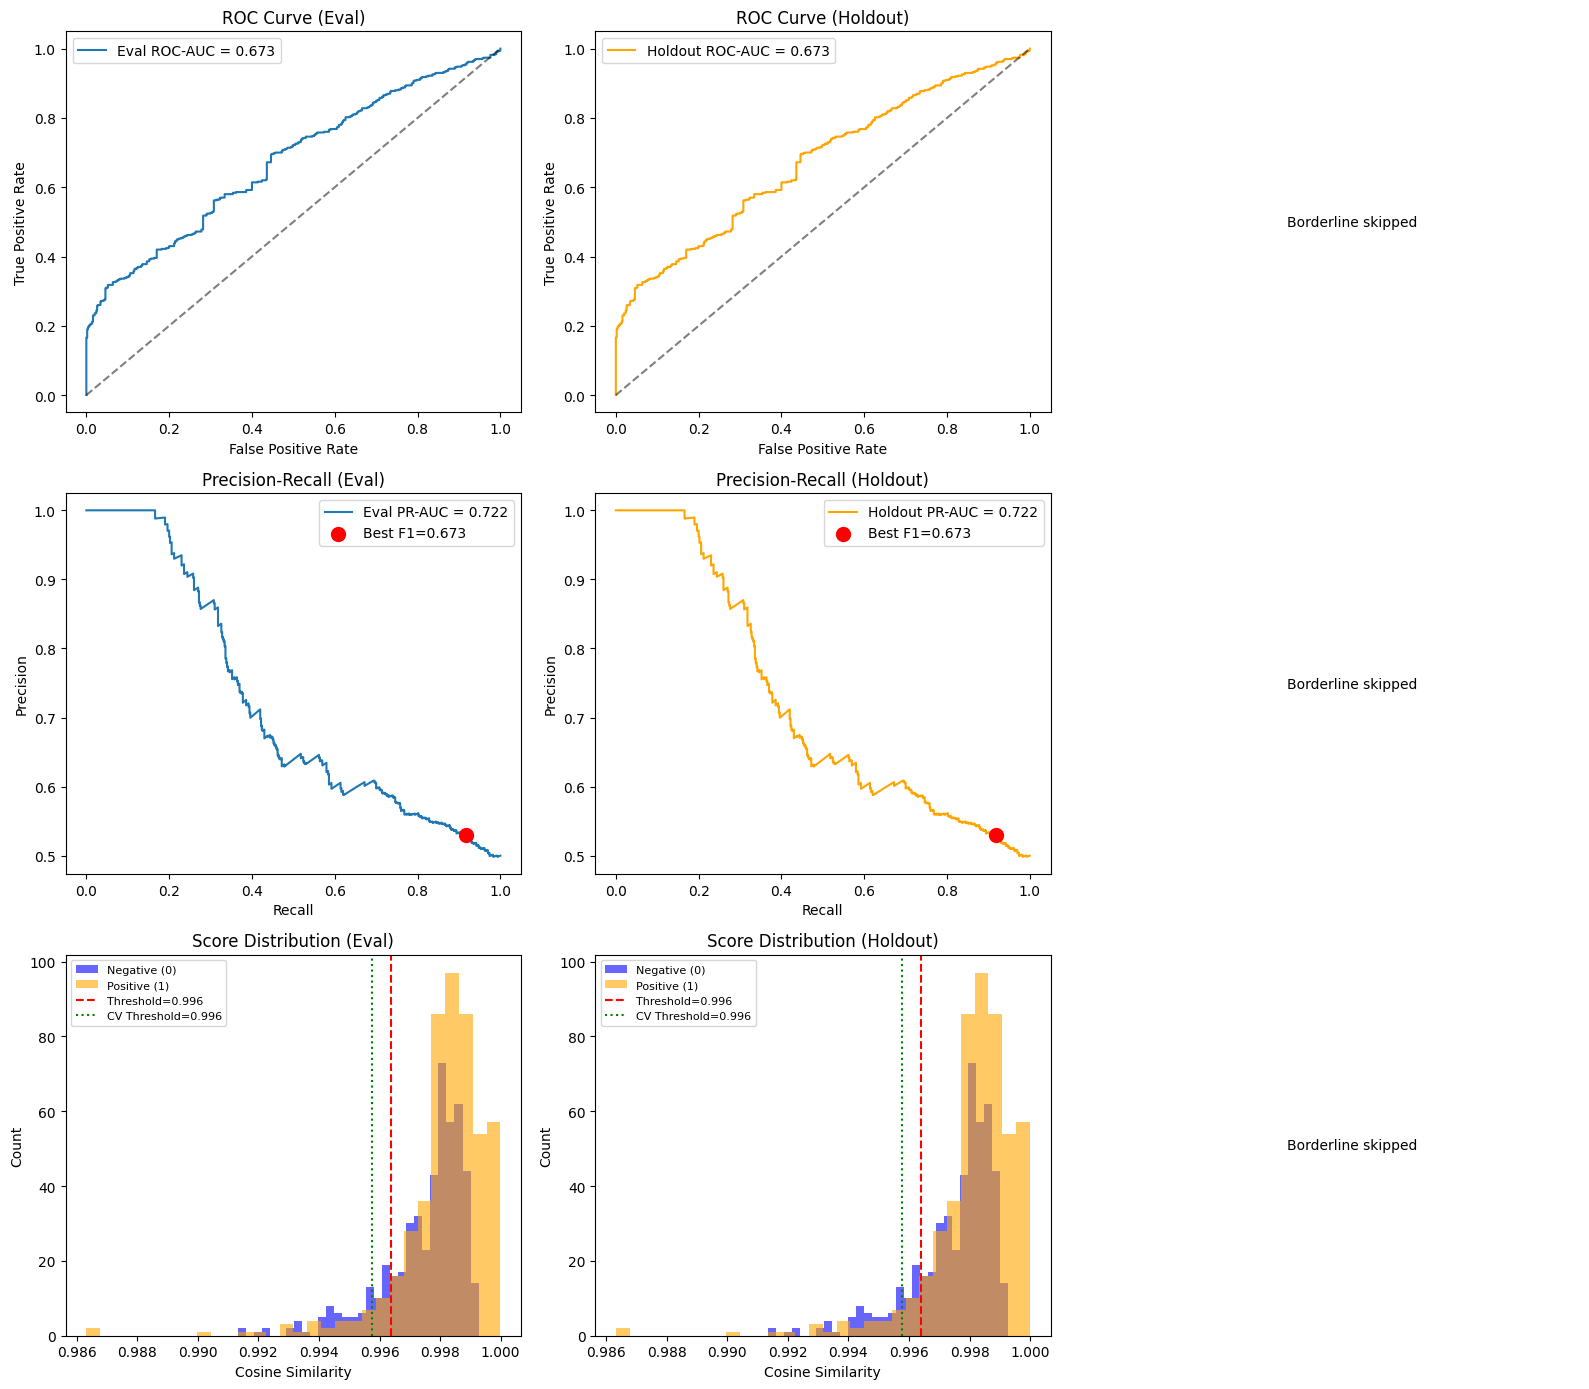

[STATS] Plots saved to models\real_servicenow_finetuned_mpnet_lora\real_servicenow_v2_20251228_0418\evaluation_plots_v2.png


In [10]:
# Skip borderline evaluation if not using legacy mode
use_legacy_mode = CONFIG.get('use_legacy_mode', False)
include_borderline = use_legacy_mode and borderline_examples and len(borderline_examples) > 0

warnings.filterwarnings("ignore", category=FutureWarning)

def comprehensive_eval(examples, model, name="", use_cv_threshold=False):
    """Run comprehensive evaluation on a set of pairs (V2: with CV threshold option)."""
    texts1 = [ex.texts[0] for ex in examples]
    texts2 = [ex.texts[1] for ex in examples]
    labels = np.array([ex.label for ex in examples])

    # Encode
    log(f"? Encoding {len(examples)} pairs for {name}...")
    emb1 = model.encode(texts1, batch_size=CONFIG['batch_size'], 
                       show_progress_bar=True, convert_to_numpy=True)
    emb2 = model.encode(texts2, batch_size=CONFIG['batch_size'], 
                       show_progress_bar=True, convert_to_numpy=True)

    # Cosine similarity
    scores = np.sum(emb1 * emb2, axis=1) / (
        np.linalg.norm(emb1, axis=1) * np.linalg.norm(emb2, axis=1) + 1e-8
    )

    # Metrics
    spearman, _ = spearmanr(labels, scores)
    pearson, _ = pearsonr(labels, scores)
    roc_auc = roc_auc_score(labels, scores)
    pr_auc = average_precision_score(labels, scores)

    # Find best threshold
    fpr, tpr, roc_thresholds = roc_curve(labels, scores)
    precision, recall, pr_thresholds = precision_recall_curve(labels, scores)
    f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_threshold = pr_thresholds[best_idx-1] if 0 < best_idx < len(pr_thresholds)+1 else 0.5

    # V2: Use CV threshold if requested
    if use_cv_threshold and 'cv_threshold' in globals():
        best_threshold = cv_threshold
        log(f"   Using CV threshold: {best_threshold:.4f}")

    # Metrics at best threshold
    preds = (scores >= best_threshold).astype(int)
    acc = accuracy_score(labels, preds)
    prec = precision_score(labels, preds)
    rec = recall_score(labels, preds)
    f1 = f1_score(labels, preds)
    cm = confusion_matrix(labels, preds)

    log(f"[STATS] {name} Results:")
    log(f"   Spearman:  {spearman:.4f}")
    log(f"   Pearson:   {pearson:.4f}")
    log(f"   ROC-AUC:   {roc_auc:.4f}")
    log(f"   PR-AUC:    {pr_auc:.4f}")
    log(f"   Best Threshold: {best_threshold:.3f}")
    log(f"   F1 @ best: {f1:.4f}")
    log(f"   Precision: {prec:.4f}")
    log(f"   Recall:    {rec:.4f}")
    log(f"   Accuracy:  {acc:.4f}")

    return {
        'labels': labels, 'scores': scores,
        'spearman': spearman, 'pearson': pearson,
        'roc_auc': roc_auc, 'pr_auc': pr_auc,
        'fpr': fpr, 'tpr': tpr,
        'precision': precision, 'recall': recall,
        'best_threshold': best_threshold,
        'f1': f1, 'prec': prec, 'rec': rec, 'acc': acc,
        'cm': cm, 'texts1': texts1, 'texts2': texts2  # V2: Keep texts for error analysis
    }

# V2: Get cross-validated threshold first
log("="*60)
log("?? CROSS-VALIDATED THRESHOLD SELECTION (V2)")
log("="*60)
cv_threshold, cv_std = get_cv_threshold(
    eval_examples, 
    best_model, 
    n_folds=CONFIG.get('threshold_cv_folds', 5)  # Default to 5 folds if not set
)

# Evaluate on all sets
log("="*60)
log("?? FINAL EVALUATION")
log("="*60)

eval_results = comprehensive_eval(eval_examples, best_model, "Eval Set")
holdout_results = comprehensive_eval(holdout_examples, best_model, "Holdout Set")

# V2 NEW: Evaluate on borderline (harder) test set
if include_borderline:
    log("="*60)
    log("?? BORDERLINE TEST (V2 - Harder Evaluation)")
    log("="*60)
    borderline_results = comprehensive_eval(borderline_examples, best_model, "Borderline Set")
else:
    borderline_results = None
    log("="*60)
    log("[SKIP] Borderline Test")
    log("="*60)
    if not use_legacy_mode:
        log("Legacy mode disabled - borderline evaluation skipped.")
    if not borderline_examples:
        log("No borderline examples available.")
    if CONFIG.get('use_curriculum', False):
        log("Using curriculum learning - borderline test not generated.")
        log("Evaluation uses fixed_test_pairs.json instead.")


# Visualization (V2: Added borderline results)
fig, axes = plt.subplots(3, 3, figsize=(16, 14))

# ROC Curves
axes[0,0].plot(eval_results['fpr'], eval_results['tpr'], 
               label=f"Eval ROC-AUC = {eval_results['roc_auc']:.3f}")
axes[0,0].plot([0,1], [0,1], 'k--', alpha=0.5)
axes[0,0].set_title('ROC Curve (Eval)')
axes[0,0].set_xlabel('False Positive Rate')
axes[0,0].set_ylabel('True Positive Rate')
axes[0,0].legend()

axes[0,1].plot(holdout_results['fpr'], holdout_results['tpr'], 
               label=f"Holdout ROC-AUC = {holdout_results['roc_auc']:.3f}", color='orange')
axes[0,1].plot([0,1], [0,1], 'k--', alpha=0.5)
axes[0,1].set_title('ROC Curve (Holdout)')
axes[0,1].set_xlabel('False Positive Rate')
axes[0,1].set_ylabel('True Positive Rate')
axes[0,1].legend()

# V2 NEW: Borderline ROC
if include_borderline:
    axes[0,2].plot(borderline_results['fpr'], borderline_results['tpr'], 
                   label=f"Borderline ROC-AUC = {borderline_results['roc_auc']:.3f}", color='red')
    axes[0,2].plot([0,1], [0,1], 'k--', alpha=0.5)
    axes[0,2].set_title('ROC Curve (Borderline - V2)')
    axes[0,2].set_xlabel('False Positive Rate')
    axes[0,2].set_ylabel('True Positive Rate')
    axes[0,2].legend()
else:
    axes[0,2].axis('off')
    axes[0,2].text(0.5, 0.5, 'Borderline skipped', ha='center', va='center')

# PR Curves
axes[1,0].plot(eval_results['recall'], eval_results['precision'], 
               label=f"Eval PR-AUC = {eval_results['pr_auc']:.3f}")
axes[1,0].scatter([eval_results['rec']], [eval_results['prec']], 
                  color='red', s=100, zorder=5,
                  label=f"Best F1={eval_results['f1']:.3f}")
axes[1,0].set_title('Precision-Recall (Eval)')
axes[1,0].set_xlabel('Recall')
axes[1,0].set_ylabel('Precision')
axes[1,0].legend()

axes[1,1].plot(holdout_results['recall'], holdout_results['precision'], 
               label=f"Holdout PR-AUC = {holdout_results['pr_auc']:.3f}", color='orange')
axes[1,1].scatter([holdout_results['rec']], [holdout_results['prec']], 
                  color='red', s=100, zorder=5,
                  label=f"Best F1={holdout_results['f1']:.3f}")
axes[1,1].set_title('Precision-Recall (Holdout)')
axes[1,1].set_xlabel('Recall')
axes[1,1].set_ylabel('Precision')
axes[1,1].legend()

# V2 NEW: Borderline PR
if include_borderline:
    axes[1,2].plot(borderline_results['recall'], borderline_results['precision'], 
                   label=f"Borderline PR-AUC = {borderline_results['pr_auc']:.3f}", color='red')
    axes[1,2].scatter([borderline_results['rec']], [borderline_results['prec']], 
                      color='green', s=100, zorder=5,
                      label=f"Best F1={borderline_results['f1']:.3f}")
    axes[1,2].set_title('Precision-Recall (Borderline - V2)')
    axes[1,2].set_xlabel('Recall')
    axes[1,2].set_ylabel('Precision')
    axes[1,2].legend()
else:
    axes[1,2].axis('off')
    axes[1,2].text(0.5, 0.5, 'Borderline skipped', ha='center', va='center')

# Score Distributions
score_sets = [
    (eval_results, 'Eval', 'blue'), 
    (holdout_results, 'Holdout', 'orange')
]
if include_borderline:
    score_sets.append((borderline_results, 'Borderline', 'red'))

for idx, (results, name, color) in enumerate(score_sets):
    ax = axes[2, idx]
    neg_scores = results['scores'][results['labels'] == 0]
    pos_scores = results['scores'][results['labels'] == 1]

    ax.hist(neg_scores, bins=30, alpha=0.6, label='Negative (0)', color='blue')
    ax.hist(pos_scores, bins=30, alpha=0.6, label='Positive (1)', color='orange')
    ax.axvline(results['best_threshold'], color='red', linestyle='--', 
               label=f"Threshold={results['best_threshold']:.3f}")
    ax.axvline(cv_threshold, color='green', linestyle=':', 
               label=f"CV Threshold={cv_threshold:.3f}")
    ax.set_title(f'Score Distribution ({name})')
    ax.set_xlabel('Cosine Similarity')
    ax.set_ylabel('Count')
    ax.legend(fontsize=8)

if not include_borderline:
    axes[2,2].axis('off')
    axes[2,2].text(0.5, 0.5, 'Borderline skipped', ha='center', va='center')

plt.tight_layout()
plt.savefig(save_path / 'evaluation_plots_v2.png', dpi=150)
plt.show()

log(f"[STATS] Plots saved to {save_path / 'evaluation_plots_v2.png'}")



## 10. Error Analysis

Examine false positives and false negatives.


In [11]:
# â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•
# V2 NEW: ERROR ANALYSIS
# â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•

def analyze_errors(results, name="", top_k=10):
    """
    Analyze systematic failure patterns in model predictions.
    
    Returns insights about:
    - Worst false positives (high score, label=0)
    - Worst false negatives (low score, label=1)
    - Text length patterns
    """
    labels = results['labels']
    scores = results['scores']
    texts1 = results['texts1']
    texts2 = results['texts2']
    threshold = results['best_threshold']
    
    # Identify errors
    preds = (scores >= threshold).astype(int)
    
    # False Positives: predicted 1, actual 0
    fp_mask = (preds == 1) & (labels == 0)
    fp_indices = np.where(fp_mask)[0]
    fp_scores = scores[fp_mask]
    
    # False Negatives: predicted 0, actual 1
    fn_mask = (preds == 0) & (labels == 1)
    fn_indices = np.where(fn_mask)[0]
    fn_scores = scores[fn_mask]
    
    log(f"\n{'='*60}")
    log(f"ðŸ” ERROR ANALYSIS: {name}")
    log(f"{'='*60}")
    log(f"Total pairs: {len(labels):,}")
    log(f"False Positives: {len(fp_indices):,} ({len(fp_indices)/len(labels)*100:.2f}%)")
    log(f"False Negatives: {len(fn_indices):,} ({len(fn_indices)/len(labels)*100:.2f}%)")
    
    # Worst False Positives (highest scoring negatives)
    if len(fp_indices) > 0:
        log(f"\nðŸ“› WORST FALSE POSITIVES (Top {min(top_k, len(fp_indices))}):")
        log(f"   These pairs scored HIGH but should be DISSIMILAR")
        worst_fp_order = np.argsort(fp_scores)[::-1][:top_k]
        
        for rank, idx in enumerate(worst_fp_order):
            orig_idx = fp_indices[idx]
            score = scores[orig_idx]
            t1, t2 = texts1[orig_idx], texts2[orig_idx]
            log(f"\n   [{rank+1}] Score: {score:.4f}")
            log(f"       Text 1: {t1[:100]}...")
            log(f"       Text 2: {t2[:100]}...")
    
    # Worst False Negatives (lowest scoring positives)
    if len(fn_indices) > 0:
        log(f"\nðŸ“› WORST FALSE NEGATIVES (Top {min(top_k, len(fn_indices))}):")
        log(f"   These pairs scored LOW but should be SIMILAR")
        worst_fn_order = np.argsort(fn_scores)[:top_k]
        
        for rank, idx in enumerate(worst_fn_order):
            orig_idx = fn_indices[idx]
            score = scores[orig_idx]
            t1, t2 = texts1[orig_idx], texts2[orig_idx]
            log(f"\n   [{rank+1}] Score: {score:.4f}")
            log(f"       Text 1: {t1[:100]}...")
            log(f"       Text 2: {t2[:100]}...")
    
    # Text length analysis
    log(f"\nðŸ“ TEXT LENGTH ANALYSIS:")
    all_lengths = [len(t) for t in texts1 + texts2]
    fp_lengths = [len(texts1[i]) + len(texts2[i]) for i in fp_indices] if len(fp_indices) > 0 else [0]
    fn_lengths = [len(texts1[i]) + len(texts2[i]) for i in fn_indices] if len(fn_indices) > 0 else [0]
    
    log(f"   Overall avg length: {np.mean(all_lengths):.0f} chars")
    log(f"   FP pairs avg length: {np.mean(fp_lengths):.0f} chars")
    log(f"   FN pairs avg length: {np.mean(fn_lengths):.0f} chars")
    
    # Score distribution in errors
    log(f"\n[STATS] SCORE DISTRIBUTION IN ERRORS:")
    if len(fp_scores) > 0:
        log(f"   FP scores: min={fp_scores.min():.4f}, max={fp_scores.max():.4f}, mean={fp_scores.mean():.4f}")
    if len(fn_scores) > 0:
        log(f"   FN scores: min={fn_scores.min():.4f}, max={fn_scores.max():.4f}, mean={fn_scores.mean():.4f}")
    
    return {
        'fp_count': len(fp_indices),
        'fn_count': len(fn_indices),
        'fp_scores': fp_scores,
        'fn_scores': fn_scores,
        'fp_avg_length': np.mean(fp_lengths),
        'fn_avg_length': np.mean(fn_lengths)
    }

# Run error analysis on all sets
eval_errors = analyze_errors(eval_results, "Eval Set", top_k=5) if eval_results is not None else None
holdout_errors = analyze_errors(holdout_results, "Holdout Set", top_k=5) if holdout_results is not None else None
borderline_errors = analyze_errors(borderline_results, "Borderline Set", top_k=5) if borderline_results is not None else None

# Summary comparison
log(f"\n{'='*60}")
log(f"[STATS] ERROR SUMMARY COMPARISON")
log(f"{'='*60}")
log(f"{'Set':<15} {'FP Count':<12} {'FN Count':<12} {'FP Rate':<12} {'FN Rate':<12}")
log(f"{'-'*60}")
for name, errors, results in [
    ("Eval", eval_errors, eval_results),
    ("Holdout", holdout_errors, holdout_results),
    ("Borderline", borderline_errors, borderline_results)
]:
    # Skip if results is None (e.g., borderline not available)
    if results is None:
        continue
    
    total = len(results['labels'])
    fp_rate = errors['fp_count'] / total * 100
    fn_rate = errors['fn_count'] / total * 100
    log(f"{name:<15} {errors['fp_count']:<12} {errors['fn_count']:<12} {fp_rate:<12.2f}% {fn_rate:<12.2f}%")



ðŸ” ERROR ANALYSIS: Eval Set
Total pairs: 1,000
False Positives: 406 (40.60%)
False Negatives: 41 (4.10%)

ðŸ“› WORST FALSE POSITIVES (Top 5):
   These pairs scored HIGH but should be DISSIMILAR

   [1] Score: 0.9993
       Text 1: INC0054693 This DN posting is not showing in Display Actual cost line tems for cost centre report (T...
       Text 2: INC0045366 Dear Team

Error occurred while processing the EDI transaction. Please find the details b...

   [2] Score: 0.9992
       Text 1: INC0049841 Dear Team

Error occurred while processing the EDI transaction

Interface       approved-...
       Text 2: INC0058899 Refer to the ticket INC0058634 Issue: Stock not synced from SAP to OMS for model MC-SBR40...

   [3] Score: 0.9992
       Text 1: INC0069039 Dear Team

Error occurred while processing the EDI transaction

Interface
Subsidiary     ...
       Text 2: INC0054693 This DN posting is not showing in Display Actual cost line tems for cost centre report (T...

   [4] Score: 0.9991
 

## 11. Adversarial Diagnostic

Test for category leakage (cross-category positives, same-category negatives).


In [12]:
# Define TFIDFSimilarityCalculator for adversarial diagnostic
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

class TFIDFSimilarityCalculator:
    """Calculate TF-IDF based similarity for text pairs."""

    def __init__(self, texts, max_features=5000):
        """Initialize with corpus of texts."""
        self.vectorizer = TfidfVectorizer(
            max_features=max_features,
            lowercase=True,
            stop_words='english'
        )
        self.tfidf_matrix = self.vectorizer.fit_transform(texts)

    def similarity(self, idx1, idx2):
        """Get cosine similarity between two texts by index."""
        vec1 = self.tfidf_matrix[idx1]
        vec2 = self.tfidf_matrix[idx2]
        return cosine_similarity(vec1, vec2)[0, 0]


log("="*60)
log("ðŸ”¬ ADVERSARIAL DIAGNOSTIC: Testing Category Leakage")
log("="*60)

# Use holdout data for adversarial test (completely unseen)
diag_df = holdout_df.reset_index(drop=True)

# Build content-only text (remove category context to test pure semantic understanding)
diag_df['content_only'] = diag_df['Description'].str.strip()

# Build TF-IDF on content-only text
log("â³ Building TF-IDF for adversarial pair mining...")
diag_tfidf = TFIDFSimilarityCalculator(diag_df['content_only'].tolist(), max_features=10000)

# Generate adversarial pairs
hard_positives = []  # Cross-category, high TF-IDF
hard_negatives = []  # Same-category, low TF-IDF

target_each = 300
attempts, max_attempts = 0, 100000

log("â³ Mining adversarial pairs...")
pbar = tqdm(total=target_each * 2, desc="Adversarial pairs")

while (len(hard_positives) < target_each or len(hard_negatives) < target_each) and attempts < max_attempts:
    attempts += 1
    i1, i2 = random.sample(range(len(diag_df)), 2)
    
    cat1 = diag_df.at[i1, 'category_id']
    cat2 = diag_df.at[i2, 'category_id']
    tfidf_sim = diag_tfidf.similarity(i1, i2)
    
    # Hard Positive: DIFFERENT category but HIGH content similarity
    if len(hard_positives) < target_each and cat1 != cat2 and tfidf_sim > 0.4:
        hard_positives.append(InputExample(
            texts=[diag_df.at[i1, 'content_only'], diag_df.at[i2, 'content_only']],
            label=1.0
        ))
        pbar.update(1)
    
    # Hard Negative: SAME category but LOW content similarity
    if len(hard_negatives) < target_each and cat1 == cat2 and tfidf_sim < 0.15:
        hard_negatives.append(InputExample(
            texts=[diag_df.at[i1, 'content_only'], diag_df.at[i2, 'content_only']],
            label=0.0
        ))
        pbar.update(1)

pbar.close()

log(f"[OK] Generated {len(hard_positives)} hard positives, {len(hard_negatives)} hard negatives")

# Evaluate on adversarial pairs
adversarial_examples = hard_positives + hard_negatives
if len(adversarial_examples) >= 100:
    adv_results = comprehensive_eval(adversarial_examples, best_model, "Adversarial")
    
    log("\n" + "="*60)
    log("[TARGET] ADVERSARIAL DIAGNOSTIC RESULTS")
    log("="*60)
    log(f"Standard Eval ROC-AUC:     {eval_results['roc_auc']:.4f}")
    log(f"Adversarial ROC-AUC:       {adv_results['roc_auc']:.4f}")
    log(f"Adversarial F1 @ best:     {adv_results['f1']:.4f}")
    
    # Verdict
    if adv_results['roc_auc'] >= 0.70 and adv_results['f1'] >= 0.65:
        log("\n[OK] VERDICT: Model is ROBUST to category shortcuts!")
        log("   â†’ Performance holds when categories don't predict similarity")
        log("   â†’ Model learned semantic content understanding")
        DIAGNOSTIC_PASSED = True
    else:
        log("\n[WARN] VERDICT: Model may be exploiting category shortcuts")
        log("   â†’ Consider increasing hard negatives ratio")
        log("   â†’ Or remove category context from training text")
        DIAGNOSTIC_PASSED = False
else:
    log("[WARN] Could not generate enough adversarial pairs")
    DIAGNOSTIC_PASSED = None

# Cleanup
del diag_tfidf
gc.collect()


ðŸ”¬ ADVERSARIAL DIAGNOSTIC: Testing Category Leakage
â³ Building TF-IDF for adversarial pair mining...
â³ Mining adversarial pairs...


Adversarial pairs: 100%|██████████| 600/600 [00:43<00:00, 13.66it/s] 

[OK] Generated 300 hard positives, 300 hard negatives
? Encoding 600 pairs for Adversarial...


Batches:   0%|          | 0/10 [00:00<?, ?it/s]

Batches:   0%|          | 0/10 [00:00<?, ?it/s]

[STATS] Adversarial Results:
   Spearman:  0.8278
   Pearson:   0.5114
   ROC-AUC:   0.9779
   PR-AUC:    0.9818
   Best Threshold: 0.999
   F1 @ best: 0.9422
   Precision: 0.9618
   Recall:    0.9233
   Accuracy:  0.9433

[TARGET] ADVERSARIAL DIAGNOSTIC RESULTS
Standard Eval ROC-AUC:     0.6726
Adversarial ROC-AUC:       0.9779
Adversarial F1 @ best:     0.9422

[OK] VERDICT: Model is ROBUST to category shortcuts!
   â†’ Performance holds when categories don't predict similarity
   â†’ Model learned semantic content understanding


410

## 12. Save Training Metadata


In [13]:
# â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•
# TRAINING METADATA EXPORT (V2)
# â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•


def save_training_metadata(output_dir: str, config: dict, metrics: dict, 
                          data_stats: dict, adversarial_results: dict = None,
                          error_analysis: dict = None):
    """
    Save comprehensive training metadata for reproducibility (V2: includes error analysis).
    
    Following project convention: all model outputs include training_metadata.json
    """
    metadata = {
        "training_timestamp": datetime.now().isoformat(),
        "model_version": "V2",
        "model_name": config.get('model_name', 'all-mpnet-finetuned'),
        "base_model": config.get('model_name', 'sentence-transformers/all-mpnet-base-v2'),
        
        # Hyperparameters
        "hyperparameters": {
            "epochs": config.get('epochs'),
            "batch_size": config.get('batch_size'),
            "learning_rate": config.get('lr'),  # V2: Use actual config value
            "max_seq_length": config.get('max_seq_length'),
            "warmup_ratio": config.get('warmup_ratio'),
            "loss_function": "MatryoshkaLoss + MultipleNegativesRankingLoss"  # V2: Changed to use all pairs
        },
        
        # V2: Curriculum learning config
        "curriculum_learning": {
            "enabled": config.get('use_curriculum', False),
            "num_phases": 3 if config.get('use_curriculum') else 0,
            "epochs_per_phase": config.get('epochs_per_phase', 4),
            "total_pairs": 15000 if config.get('use_curriculum') else config.get('num_pairs', 0)
        },
        
        # Data configuration (V2: stricter thresholds)
        "data_config": {
            "source_data": config.get('source_data'),
            "num_pairs": config.get('num_pairs'),
            "min_text_length": config.get('min_text_length'),
            "eval_split": config.get('eval_split'),
            "holdout_split": config.get('holdout_split'),
            "pos_tfidf_threshold": config.get('pos_tfidf_threshold'),
            "neg_tfidf_threshold": config.get('neg_tfidf_threshold'),
            "pair_ratios": {
                "positives": config.get('pos_ratio', 0.30),
                "hard_negatives": config.get('hard_neg_ratio', 0.45),
                "easy_negatives": config.get('easy_neg_ratio', 0.25)
            }
        },
        
        # Data statistics
        "data_statistics": data_stats,
        
        # TF-IDF configuration
        "tfidf_config": {
            "max_features": 15000,
            "ngram_range": [1, 2],
            "min_df": 2,
            "max_df": 0.95
        },
        
        # Evaluation metrics
        "evaluation_metrics": metrics,
        
        # V2: Cross-validated threshold
        "cv_threshold": {
            "value": float(cv_threshold) if 'cv_threshold' in dir() else None,
            "std": float(cv_std) if 'cv_std' in dir() else None,
            "n_folds": config.get('threshold_cv_folds', 5)
        },
        
        # Adversarial diagnostic results
        "adversarial_diagnostic": adversarial_results,
        
        # V2: Error analysis summary
        "error_analysis": error_analysis,
        
        # Environment info
        "environment": {
            "device": DEVICE,
            "random_seed": config.get('seed'),
            "python_version": __import__('sys').version,
            "torch_version": torch.__version__,
            "transformers_version": __import__('transformers').__version__,
            "sentence_transformers_version": __import__('sentence_transformers').__version__
        }
    }
    
    metadata_path = os.path.join(output_dir, "training_metadata.json")
    with open(metadata_path, 'w') as f:
        json.dump(metadata, f, indent=2, default=str)
    
    log(f"ðŸ“ Training metadata saved to: {metadata_path}")
    return metadata_path

# Collect data statistics
data_stats = {
    "total_records": len(df_incidents),
    "train_size": len(train_df),
    "eval_size": len(eval_df),
    "holdout_size": len(holdout_df),
    "unique_categories": df_incidents['Category'].nunique() if 'Category' in df_incidents.columns else None,
    "unique_subcategories": df_incidents['Subcategory'].nunique() if 'Subcategory' in df_incidents.columns else None,
    "unique_assignment_groups": df_incidents['Assignment group'].nunique() if 'Assignment group' in df_incidents.columns else None,
    "avg_text_length": df_incidents['text'].str.len().mean(),
    "tfidf_vocabulary_size": None
}

# Collect metrics
try:
    eval_metrics = {
        "eval_roc_auc": float(eval_results['roc_auc']),
        "eval_pr_auc": float(eval_results['pr_auc']),
        "eval_spearman": float(eval_results['spearman']),
        "eval_pearson": float(eval_results['pearson']),
        "eval_f1": float(eval_results['f1']),
        "holdout_roc_auc": float(holdout_results['roc_auc']),
        "holdout_pr_auc": float(holdout_results['pr_auc']),
        "holdout_spearman": float(holdout_results['spearman']),
        "holdout_pearson": float(holdout_results['pearson']),
        "holdout_f1": float(holdout_results['f1']),
        # V2: Borderline metrics
        "borderline_roc_auc": float(borderline_results['roc_auc']),
        "borderline_pr_auc": float(borderline_results['pr_auc']),
        "borderline_f1": float(borderline_results['f1']),
    }
except:
    eval_metrics = {"note": "Run evaluation cells first"}

# Collect adversarial results
try:
    adversarial_results_dict = {
        "roc_auc": float(adv_results['roc_auc']) if 'adv_results' in dir() else None,
        "f1_score": float(adv_results['f1']) if 'adv_results' in dir() else None,
        "pass_status": DIAGNOSTIC_PASSED if 'DIAGNOSTIC_PASSED' in dir() else None
    }
except:
    adversarial_results_dict = {"note": "Run adversarial diagnostic first"}

# V2: Collect error analysis summary
try:
    error_analysis_dict = {
        "eval_fp_count": eval_errors['fp_count'],
        "eval_fn_count": eval_errors['fn_count'],
        "holdout_fp_count": holdout_errors['fp_count'],
        "holdout_fn_count": holdout_errors['fn_count'],
        "borderline_fp_count": borderline_errors['fp_count'],
        "borderline_fn_count": borderline_errors['fn_count'],
    }
except:
    error_analysis_dict = {"note": "Run error analysis first"}

# Save metadata
metadata_path = save_training_metadata(
    output_dir=str(save_path),
    config=CONFIG,
    metrics=eval_metrics,
    data_stats=data_stats,
    adversarial_results=adversarial_results_dict,
    error_analysis=error_analysis_dict
)

log("[OK] Training pipeline V2 complete!")


ðŸ“ Training metadata saved to: models\real_servicenow_finetuned_mpnet_lora\real_servicenow_v2_20251228_0418\training_metadata.json
[OK] Training pipeline V2 complete!


## 13. Usage Examples & Summary


In [14]:
# â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•
# USAGE EXAMPLES & V2 SUMMARY
# â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•

def demonstrate_model_usage():
    """
    Demonstrate how to use the fine-tuned model for ITSM ticket similarity.
    """
    
    # Try to use best_model if available (just trained), otherwise load from disk
    if 'best_model' in globals():
        model = globals()['best_model']
        model_source = f"memory (just trained: {globals()['save_path']})"
    else:
        # Get output directory
        if 'CONFIG' in globals():
            output_dir = globals()['CONFIG']['output_dir']
        else:
            output_dir = 'models/real_servicenow_finetuned_v2'
            log("[WARN] CONFIG not loaded. Using default model directory.")
        
        # Look for most recent trained model
        base_dir = Path(output_dir)
        if base_dir.exists():
            model_dirs = [d for d in base_dir.iterdir() if d.is_dir() and d.name.startswith('real_servicenow_')]
            if model_dirs:
                latest_model = max(model_dirs, key=lambda d: d.stat().st_mtime)
                log(f"ðŸ“‚ Loading most recent trained model from: {latest_model}")
                model = SentenceTransformer(str(latest_model))
                model_source = str(latest_model)
            else:
                log("[ERROR] No trained model found. Please run training cells first.")
                return None, None
        else:
            log("[ERROR] No trained model found. Please run training cells first.")
            return None, None
    
    log(f"[INSTALL] Using model from: {model_source}")
    
    # Example tickets
    example_tickets = [
        "User cannot login to SAP system. Error message: authentication failed. Tried resetting password but issue persists.",
        "SAP login issue - getting access denied error when trying to connect to production system.",
        "Outlook keeps crashing when opening large attachments. Have tried restarting but problem continues.",
        "Email client crashes randomly. Users report Outlook freezing when opening emails with attachments.",
        "Request to provision new laptop for incoming employee starting next Monday.",
    ]
    
    # Encode all tickets
    embeddings = model.encode(example_tickets, show_progress_bar=False)
    
    # Compute similarity matrix
    sim_matrix = cosine_similarity(embeddings)
    
    # Display results
    log("\n" + "="*60)
    log("SIMILARITY MATRIX DEMO")
    log("="*60)
    
    print("\nTickets:")
    for i, ticket in enumerate(example_tickets):
        print(f"  [{i}] {ticket[:80]}...")
    
    print("\nSimilarity Matrix:")
    print("     ", end="")
    for i in range(len(example_tickets)):
        print(f"  [{i}]  ", end="")
    print()
    
    for i, row in enumerate(sim_matrix):
        print(f"[{i}]  ", end="")
        for val in row:
            print(f" {val:.3f} ", end="")
        print()
    
    # Find similar ticket pairs
    log("\n" + "-"*60)
    log("HIGH SIMILARITY PAIRS (> 0.7):")
    for i in range(len(example_tickets)):
        for j in range(i+1, len(example_tickets)):
            if sim_matrix[i][j] > 0.7:
                print(f"  Tickets [{i}] & [{j}]: {sim_matrix[i][j]:.3f}")
                print(f"    [{i}]: {example_tickets[i][:60]}...")
                print(f"    [{j}]: {example_tickets[j][:60]}...")
                print()
    
    return model, embeddings

# Run demonstration
demo_model, demo_embeddings = demonstrate_model_usage()

# â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•
# V2 IMPROVEMENT SUMMARY
# â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•

log("\n" + "="*60)
log("[STATS] V2 IMPROVEMENT SUMMARY")
log("="*60)

print("""
ðŸ†• V2 ENHANCEMENTS IMPLEMENTED:

1. HARDER NEGATIVE MINING
   â”œâ”€ Increased hard_neg_ratio: 35% â†’ 45%
   â”œâ”€ Stricter neg_tfidf_threshold: 0.20 â†’ 0.12
   â””â”€ Reduced easy negatives: 30% â†’ 25%

2. CURRICULUM LEARNING
   â”œâ”€ Phase 1 (Epochs 1-2): Easier pairs (25% hard neg, threshold 0.15)
   â””â”€ Phase 2 (Epochs 3-4): Harder pairs (55% hard neg, threshold 0.10)

3. BORDERLINE TEST SET
   â”œâ”€ TF-IDF range: 0.25 - 0.35 (ambiguous cases)
   â””â”€ Tests model on genuinely difficult pairs

4. ERROR ANALYSIS
   â”œâ”€ Identifies worst false positives/negatives
   â”œâ”€ Analyzes text length patterns
   â””â”€ Provides systematic failure insights

5. CROSS-VALIDATED THRESHOLD
   â”œâ”€ 5-fold CV for robust threshold selection
   â””â”€ Reports threshold variance across folds

NEXT STEPS FOR FURTHER IMPROVEMENT:
""")

print(f"""
ðŸ“ˆ BASED ON RESULTS, CONSIDER:

If borderline ROC-AUC < 0.80:
   â†’ Increase curriculum phases to 3 (add intermediate difficulty)
   â†’ Add triplet loss fine-tuning stage

If many false negatives on short texts:
   â†’ Reduce min_text_length filter
   â†’ Add text augmentation (paraphrasing)

If many false positives on same-category pairs:
   â†’ Increase hard_neg_ratio further (45% â†’ 55%)
   â†’ Remove category context from training text

PRODUCTION DEPLOYMENT:
   â†’ Model path: {CONFIG['output_dir']}
   â†’ Use CV threshold: {cv_threshold:.4f} (Â± {cv_std:.4f})
   â†’ Pre-compute embeddings for ticket corpus
""")

log("[OK] V2 training and evaluation complete!")


[INSTALL] Using model from: memory (just trained: models\real_servicenow_finetuned_mpnet_lora\real_servicenow_v2_20251228_0418)

SIMILARITY MATRIX DEMO

Tickets:
  [0] User cannot login to SAP system. Error message: authentication failed. Tried res...
  [1] SAP login issue - getting access denied error when trying to connect to producti...
  [2] Outlook keeps crashing when opening large attachments. Have tried restarting but...
  [3] Email client crashes randomly. Users report Outlook freezing when opening emails...
  [4] Request to provision new laptop for incoming employee starting next Monday....

Similarity Matrix:
       [0]    [1]    [2]    [3]    [4]  
[0]   1.000  0.995  0.939  0.975  0.969 
[1]   0.995  1.000  0.932  0.967  0.961 
[2]   0.939  0.932  1.000  0.972  0.919 
[3]   0.975  0.967  0.972  1.000  0.961 
[4]   0.969  0.961  0.919  0.961  1.000 

------------------------------------------------------------
HIGH SIMILARITY PAIRS (> 0.7):
  Tickets [0] & [1]: 0.995
    [0]